# 4 · Prediction test and measurement validity

**Prediction test (P5, pre-registered).** Before training, a first-order *overlap score* was computed for four corpora on
the untrained model. One SGD step on corpus D moves the refusal gap by −lr·(∇gap·ḡ_D), so s = (∇gap·ḡ_D)/gap predicts
relative erosion per framing. It was calibrated on the two corpora already measured (code, chat-like), and predictions
for **legal** (US case law) and **news** (CNN/DailyMail) were written before training (`R3_forecasts_preregistered_Qwen3.5-0.8B.json`,
timestamped). Then all three were trained in the gentle regime, identical to the laptop runs.

**Generation check.** Does the first-token refusal score match what the model actually writes? Greedy responses
(48 tokens) to the same requests, classified by a fixed keyword list, on the base model and six saved checkpoints.

In [1]:
import sys, os; sys.path.insert(0, ".")
import numpy as np, pandas as pd
from kwm import *
setup(); pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
P, S = load("forecast/R3_forecasts_preregistered_Qwen3.5-0.8B.json"), load("forecast/R3_overlap-scores_before-training_Qwen3.5-0.8B.json")["corpora"]
CH = ("text_plain", "text_wrap", "image_wrap"); NAME = {"ood": "code", "benign": "chat-like", "legal": "legal", "news": "news"}
meas = {d: load(f"forecast/{f}")[-1] for d, f in (("legal", "R3_test-run_Qwen3.5-0.8B_legal_gentle.json"), ("news", "R3_test-run_Qwen3.5-0.8B_news_gentle.json"), ("benign", "R3_anchor-run_Qwen3.5-0.8B_chat_gentle.json"))}
rows = []
for d in ("ood", "benign", "legal", "news"):
    for c in CH:
        known = P["known"].get(d, {}).get(c); m = 100 * (1 - meas[d]["kept_" + c]) if d in meas else None
        rows.append({"corpus": NAME[d], "channel": c, "score s": round(S[d][c]["s"], 1), "± se": round(S[d][c]["s_se"], 1),
                     "laptop (known) %": known, "predicted %": round(P["k"] * S[d][c]["s"], 2) if d in ("legal", "news") else None,
                     "Kaggle measured %": None if m is None else round(m, 2)})
print(f"predictions written {P['written']}; retrodiction Spearman {P['retrodiction_spearman']:.2f}; k = {P['k']:.3f}")
pd.DataFrame(rows).set_index(["corpus", "channel"]).astype(object).fillna("–")   # empty = not applicable (calibration corpora have no forecast)

predictions written 2026-09-25 18:06:17 UTC; retrodiction Spearman 0.94; k = 0.198


/var/folders/w0/l8fyt7vs4z7101vjrxfdlhrr0000gn/T/ipykernel_55596/1875130098.py:16: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  pd.DataFrame(rows).set_index(["corpus", "channel"]).astype(object).fillna("–")   # empty = not applicable (calibration corpora have no forecast)


score s  ± se laptop (known) % predicted % Kaggle measured %
corpus    channel                                                                 
code      text_plain     10.9   1.8            0.912           –                 –
          text_wrap      19.1   2.7            2.479           –                 –
          image_wrap     18.1   3.8            3.472           –                 –
chat-like text_plain     41.3   2.7            5.786           –              5.78
          text_wrap      64.8   4.3           13.965           –              13.8
          image_wrap    148.8  10.4            29.87           –             29.85
legal     text_plain     10.9   1.4                –        2.15              1.23
          text_wrap      15.0   1.9                –        2.98               6.1
          image_wrap     -7.2   4.0                –       -1.42               0.2
news      text_plain     16.1   2.6                –        3.18              1.46
          text_wrap      17.5   3.5                –        3.45              6.23
          image_wrap     38.6   5.9                –        7.63             -1.59

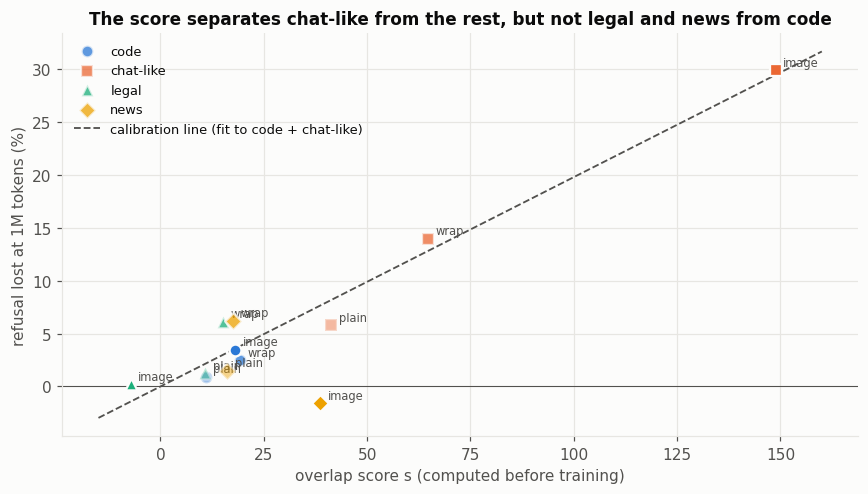

pre-registered verdict: NOT SUPPORTED | platform factor (Kaggle chat-like / laptop) 0.994


In [2]:
fig, ax = plt.subplots(figsize=(8, 4.6))
for d, col, mk in (("ood", BLUE, "o"), ("benign", ORANGE, "s"), ("legal", AQUA, "^"), ("news", YELLOW, "D")):
    for c, alpha in zip(CH, (0.45, 0.75, 1.0)):
        x = S[d][c]["s"]; y = P["known"][d][c] if d in P["known"] else 100 * (1 - meas[d]["kept_" + c])
        ax.scatter(x, y, color=col, marker=mk, s=60, alpha=alpha, edgecolor=SURFACE, linewidth=1.5, label=NAME[d] if c == "text_wrap" else None, zorder=3)
        ax.annotate(c.replace("text_", "").replace("_wrap", ""), (x, y), xytext=(5, 3), textcoords="offset points", fontsize=7.5, color=INK2)
xs = np.linspace(-15, 160, 2); ax.plot(xs, P["k"] * xs, color=INK2, ls="--", lw=1.2, label=f"calibration line (fit to code + chat-like)")
ax.axhline(0, color=INK2, lw=0.7); ax.set_xlabel("overlap score s (computed before training)"); ax.set_ylabel("refusal lost at 1M tokens (%)")
ax.legend(loc="upper left", fontsize=8.5); ax.set_title("The score separates chat-like from the rest, but not legal and news from code")
fig.tight_layout(); plt.show()
C = load("forecast/R3_verdict_Qwen3.5-0.8B.json"); print(f"pre-registered verdict: {C['primary']} | platform factor (Kaggle chat-like / laptop) {C['platform_factor']:.3f}")

**Reading it.** The score is computed before training, and it ranks the six known rates almost perfectly
(Spearman 0.94). Legal and news were both predicted to be milder than code. Measured, they each erode wrapped-text
refusal ~6% (2.4× code, under half of chat-like), and neither touches image refusal; the score predicted +7.6% for
news images. By the pre-registered rule, 1 of 4 tests pass: **P5 not supported**. The first-order score separates
dangerous data from mild data, but cannot order the mild corpora. The Kaggle chat-like anchor matches the laptop to
within 1%, so gentle-regime numbers hold across hardware.

## Generation check

In [3]:
G = load("measurement/M1_first-token-vs-generated-refusal_Qwen3.5-0.8B.json")["models"]; base = G["base"]
rows = []
for name, r in G.items():
    for c, v in r.items():
        rows.append({"model": name, "channel": c, "first-token gap": round(v["gap"], 2), "gap vs base": f"{100 * (v['gap'] / base[c]['gap'] - 1):+.0f}%",
                     "generated refusal, harmful": round(v["rate_harmful"], 2), "generated refusal, harmless": round(v["rate_harmless"], 2),
                     "AUROC first-token → generated": None if v["auroc"] is None else round(v["auroc"], 2)})
pd.DataFrame(rows).set_index(["model", "channel"])

first-token gap gap vs base  generated refusal, harmful  generated refusal, harmless  AUROC first-token → generated
model          channel                                                                                                                        
base           text_plain             6.10         +0%                        0.81                         0.00                           0.97
               text_wrap              5.84         +0%                        0.91                         0.03                           1.00
               image_wrap             1.85         +0%                        0.38                         0.00                           0.80
benign_131072  text_plain             5.89         -3%                        0.75                         0.00                           0.95
               text_wrap              5.42         -7%                        0.91                         0.00                           0.98
               image_wrap             1.52        -18%                        0.41                         0.00                           0.73
benign_512000  text_plain             5.65         -7%                        0.75                         0.00                           0.94
               text_wrap              4.86        -17%                        0.81                         0.00                           0.95
               image_wrap             1.29        -30%                        0.36                         0.00                           0.70
benign_1003520 text_plain             5.72         -6%                        0.73                         0.00                           0.94
               text_wrap              4.98        -15%                        0.83                         0.00                           0.95
               image_wrap             1.26        -32%                        0.39                         0.00                           0.62
ood_131072     text_plain             6.03         -1%                        0.78                         0.00                           0.97
               text_wrap              5.66         -3%                        0.91                         0.02                           0.99
               image_wrap             1.71         -8%                        0.38                         0.00                           0.78
ood_512000     text_plain             6.01         -2%                        0.78                         0.00                           0.96
               text_wrap              5.62         -4%                        0.91                         0.02                           0.99
               image_wrap             1.69         -9%                        0.38                         0.00                           0.75
ood_1003520    text_plain             6.02         -1%                        0.77                         0.00                           0.96
               text_wrap              5.65         -3%                        0.86                         0.00                           0.99
               image_wrap             1.73         -7%                        0.41                         0.00                           0.77

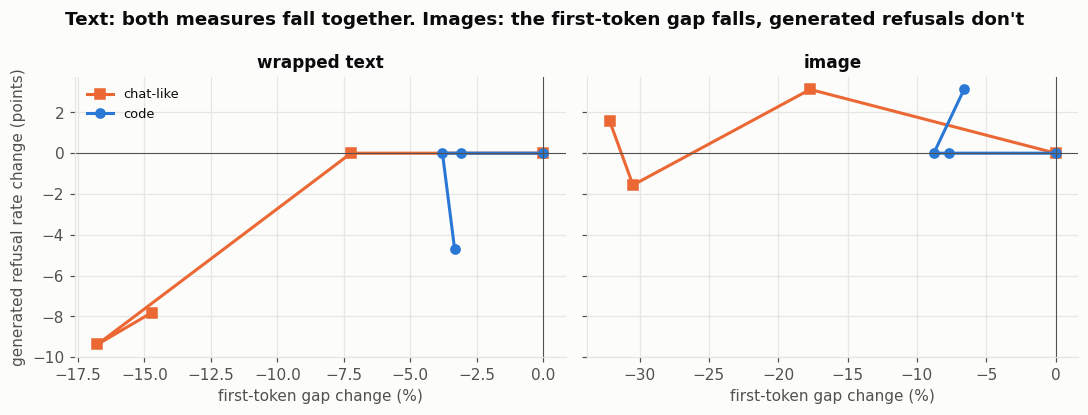

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, c, title in ((axes[0], "text_wrap", "wrapped text"), (axes[1], "image_wrap", "image")):
    for arm, col, mk in (("benign", ORANGE, "s"), ("ood", BLUE, "o")):
        pts = [(0, 0.0, 0.0)] + [(int(n.split("_")[-1]), 100 * (G[n][c]["gap"] / base[c]["gap"] - 1), 100 * (G[n][c]["rate_harmful"] - base[c]["rate_harmful"]))
                                 for n in G if n.startswith(arm)]
        pts.sort(); ax.plot([p[1] for p in pts], [p[2] for p in pts], color=col, marker=mk, label=NAME[arm])
    ax.axhline(0, color=INK2, lw=0.7); ax.axvline(0, color=INK2, lw=0.7); ax.set_title(title); ax.set_xlabel("first-token gap change (%)")
axes[0].set_ylabel("generated refusal rate change (points)"); axes[0].legend(fontsize=8.5)
fig.suptitle("Text: both measures fall together. Images: the first-token gap falls, generated refusals don't", fontweight="bold"); fig.tight_layout(); plt.show()

**Reading it.** For text, the first-token score predicts generated refusals almost perfectly (AUROC 0.97–1.00)
and falls with them over training. For images, it predicts them adequately at baseline (0.80), but not over training:
the image gap fell up to 32% while harmful-image refusals in generated text stayed at ~0.38. At 0.8B, image-refusal
erosion is therefore erosion of the *inclination* to refuse. It needs a longer-generation, stronger-judge check before
it can be called more harmful compliance. Keyword judges also miss partial compliance, so this is a lower bar than a
model judge.